# **Automatidata project**
**Course 4 - Regression Analysis: Simplify complex data relationships**

The data consulting firm Automatidata has recently hired you as the newest member of their data analytics team. Their newest client, the NYC Taxi and Limousine Commission (New York City TLC), wants the Automatidata team to build a multiple linear regression model to predict taxi fares using existing data that was collected over the course of a year. The team is getting closer to completing the project, having completed an initial plan of action, initial Python coding work, EDA, and A/B testing.

The Automatidata team has reviewed the results of the A/B testing. Now it’s time to work on predicting the taxi fare amounts. You’ve impressed your Automatidata colleagues with your hard work and attention to detail. The data team believes that you are ready to build the regression model and update the client New York City TLC about your progress.

A notebook was structured and prepared to help you in this project. Please complete the following questions.

# Course 4 End-of-course project: Build a multiple linear regression model

In this activity, you will build a multiple linear regression model. As you've learned, multiple linear regression helps you estimate the linear relationship between one continuous dependent variable and two or more independent variables. For data science professionals, this is a useful skill because it allows you to consider more than one variable against the variable you're measuring against. This opens the door for much more thorough and flexible analysis to be completed. 

Completing this activity will help you practice planning out and buidling a multiple linear regression model based on a specific business need. The structure of this activity is designed to emulate the proposals you will likely be assigned in your career as a data professional. Completing this activity will help prepare you for those career moments.
<br/>

**The purpose** of this project is to demostrate knowledge of EDA and a multiple linear regression model

**The goal** is to build a multiple linear regression model and evaluate the model
<br/>
*This activity has three parts:*

**Part 1:** EDA & Checking Model Assumptions
* What are some purposes of EDA before constructing a multiple linear regression model?

**Part 2:** Model Building and evaluation
* What resources do you find yourself using as you complete this stage?

**Part 3:** Interpreting Model Results

* What key insights emerged from your model(s)?

* What business recommendations do you propose based on the models built?

Follow the instructions and answer the questions below to complete the activity. Then, you will complete an Executive Summary using the questions listed on the PACE Strategy Document.

Be sure to complete this activity before moving on. The next course item will provide you with a completed exemplar to compare to your own work.

# Build a multiple linear regression model

<img src="images/Pace.png" width="100" height="100" align=left>

# **PACE stages**


Throughout these project notebooks, you'll see references to the problem-solving framework PACE. The following notebook components are labeled with the respective PACE stage: Plan, Analyze, Construct, and Execute.

<img src="images/Plan.png" width="100" height="100" align=left>


## PACE: **Plan**

Consider the questions in your PACE Strategy Document to reflect on the Plan stage.


### Task 1. Imports and loading
Import the packages that you've learned are needed for building linear regression models.

In [2]:
#==> ENTER YOUR CODE HERE

# Packages for numerics + dataframes
import pandas as pd
import numpy as np

# Packages for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Packages for date conversions (to calculate trip durations, etc.)
from datetime import datetime

# Packages for OLS, MLR, and model evaluation
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


**Note:** `Pandas` is used to load the NYC TLC dataset. As shown in this cell, the dataset has been automatically loaded in for you. You do not need to download the .csv file, or provide more code, in order to access the dataset and proceed with this lab. Please continue with this activity by completing the following instructions.

In [4]:
df0 = pd.read_csv("2017_Yellow_Taxi_Trip_Data.csv")


<img src="images/Analyze.png" width="100" height="100" align=left>

## PACE: **Analyze**

In this stage, consider the following question where applicable to complete your code response:

* What are some purposes of EDA before constructing a multiple linear regression model?


🔹 Purposes of EDA before Regression
Understand variable distributions  
Check how fare amounts, trip distances, and passenger counts are spread. This helps identify skewness, outliers, or unrealistic values (like zero‑distance trips).

Detect anomalies and clean data  
Spot missing values, invalid passenger counts, or extreme fares that could distort the regression model.

Explore relationships  
Use scatterplots, correlation matrices, and group comparisons to see how predictors (trip distance, duration, payment type) relate to the dependent variable (fare amount).

Check assumptions  
Regression assumes linearity, normality of residuals, and no multicollinearity. EDA helps you test these assumptions before fitting the model.

Feature selection  
Decide which independent variables are most relevant. For example, trip distance is likely a strong predictor, while passenger count may have weaker influence.

Business context validation  
Ensure that the variables you plan to include make sense for NYC TLC’s goals (predicting fares to help drivers and optimize pricing).

👉 In short, EDA is the diagnostic stage: it ensures your data is clean, your predictors are meaningful, and your regression model will be valid and interpretable.

### Task 2a. Explore data with EDA

Analyze and discover data, looking for correlations, missing data, outliers, and duplicates.

Start with `.shape` and `.info()`.

In [5]:
#==> ENTER YOUR CODE HERE

# Check the shape of the dataset (rows, columns)
print("Dataset shape:", df0.shape)

# Get information about columns, data types, and non-null counts
print("\nDataset info:")
print(df0.info())



Dataset shape: (22699, 18)

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             22699 non-null  int64  
 1   VendorID               22699 non-null  int64  
 2   tpep_pickup_datetime   22699 non-null  object 
 3   tpep_dropoff_datetime  22699 non-null  object 
 4   passenger_count        22699 non-null  int64  
 5   trip_distance          22699 non-null  float64
 6   RatecodeID             22699 non-null  int64  
 7   store_and_fwd_flag     22699 non-null  object 
 8   PULocationID           22699 non-null  int64  
 9   DOLocationID           22699 non-null  int64  
 10  payment_type           22699 non-null  int64  
 11  fare_amount            22699 non-null  float64
 12  extra                  22699 non-null  float64
 13  mta_tax                22699 non-null  float64
 14  tip_amount  

Check for missing data and duplicates using `.isna()` and `.drop_duplicates()`.

In [6]:
#==> ENTER YOUR CODE HERE

# Check for missing values in each column
missing_data = df0.isna().sum()
print("Missing values per column:\n", missing_data)

# Check for duplicate rows
duplicate_count = df0.duplicated().sum()
print("\nNumber of duplicate rows:", duplicate_count)

# Optionally, drop duplicates if needed
df0 = df0.drop_duplicates()
print("\nDataset shape after dropping duplicates:", df0.shape)


Missing values per column:
 Unnamed: 0               0
VendorID                 0
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
passenger_count          0
trip_distance            0
RatecodeID               0
store_and_fwd_flag       0
PULocationID             0
DOLocationID             0
payment_type             0
fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
dtype: int64

Number of duplicate rows: 0

Dataset shape after dropping duplicates: (22699, 18)


Use `.describe()`.

In [7]:
#==> ENTER YOUR CODE HERE

# Generate descriptive statistics for numeric columns
desc_stats = df0.describe()
print(desc_stats)


         Unnamed: 0      VendorID  passenger_count  trip_distance  \
count  2.269900e+04  22699.000000     22699.000000   22699.000000   
mean   5.675849e+07      1.556236         1.642319       2.913313   
std    3.274493e+07      0.496838         1.285231       3.653171   
min    1.212700e+04      1.000000         0.000000       0.000000   
25%    2.852056e+07      1.000000         1.000000       0.990000   
50%    5.673150e+07      2.000000         1.000000       1.610000   
75%    8.537452e+07      2.000000         2.000000       3.060000   
max    1.134863e+08      2.000000         6.000000      33.960000   

         RatecodeID  PULocationID  DOLocationID  payment_type   fare_amount  \
count  22699.000000  22699.000000  22699.000000  22699.000000  22699.000000   
mean       1.043394    162.412353    161.527997      1.336887     13.026629   
std        0.708391     66.633373     70.139691      0.496211     13.243791   
min        1.000000      1.000000      1.000000      1.000000 

### Task 2b. Convert pickup & dropoff columns to datetime


In [8]:
#==> ENTER YOUR CODE HERE

# Inspect the first few rows of pickup and dropoff columns
print(df0[['tpep_pickup_datetime', 'tpep_dropoff_datetime']].head())

# Check data types of these columns
print("\nData types:")
print(df0[['tpep_pickup_datetime', 'tpep_dropoff_datetime']].dtypes)



     tpep_pickup_datetime   tpep_dropoff_datetime
0   03/25/2017 8:55:43 AM   03/25/2017 9:09:47 AM
1   04/11/2017 2:53:28 PM   04/11/2017 3:19:58 PM
2   12/15/2017 7:26:56 AM   12/15/2017 7:34:08 AM
3   05/07/2017 1:17:59 PM   05/07/2017 1:48:14 PM
4  04/15/2017 11:32:20 PM  04/15/2017 11:49:03 PM

Data types:
tpep_pickup_datetime     object
tpep_dropoff_datetime    object
dtype: object


In [10]:
#==> ENTER YOUR CODE HERE

# Convert pickup and dropoff columns to datetime format
df0['tpep_pickup_datetime'] = pd.to_datetime(df0['tpep_pickup_datetime'])
df0['tpep_dropoff_datetime'] = pd.to_datetime(df0['tpep_dropoff_datetime'])

# Verify conversion
print(df0[['tpep_pickup_datetime', 'tpep_dropoff_datetime']].dtypes)
print(df0[['tpep_pickup_datetime', 'tpep_dropoff_datetime']].head())


tpep_pickup_datetime     datetime64[ns]
tpep_dropoff_datetime    datetime64[ns]
dtype: object
  tpep_pickup_datetime tpep_dropoff_datetime
0  2017-03-25 08:55:43   2017-03-25 09:09:47
1  2017-04-11 14:53:28   2017-04-11 15:19:58
2  2017-12-15 07:26:56   2017-12-15 07:34:08
3  2017-05-07 13:17:59   2017-05-07 13:48:14
4  2017-04-15 23:32:20   2017-04-15 23:49:03


### Task 2c. Create duration column

Create a new column called `duration` that represents the total number of minutes that each taxi ride took.

In [11]:
#==> ENTER YOUR CODE HERE

# Create duration column in minutes
df0['duration'] = (df0['tpep_dropoff_datetime'] - df0['tpep_pickup_datetime']).dt.total_seconds() / 60

# Quick check
print(df0[['tpep_pickup_datetime', 'tpep_dropoff_datetime', 'duration']].head())


  tpep_pickup_datetime tpep_dropoff_datetime   duration
0  2017-03-25 08:55:43   2017-03-25 09:09:47  14.066667
1  2017-04-11 14:53:28   2017-04-11 15:19:58  26.500000
2  2017-12-15 07:26:56   2017-12-15 07:34:08   7.200000
3  2017-05-07 13:17:59   2017-05-07 13:48:14  30.250000
4  2017-04-15 23:32:20   2017-04-15 23:49:03  16.716667


### Outliers

Call `df.info()` to inspect the columns and decide which ones to check for outliers.

In [12]:
#==> ENTER YOUR CODE HERE

# Inspect dataset structure and column data types
print(df0.info())




<class 'pandas.core.frame.DataFrame'>
Int64Index: 22699 entries, 0 to 22698
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Unnamed: 0             22699 non-null  int64         
 1   VendorID               22699 non-null  int64         
 2   tpep_pickup_datetime   22699 non-null  datetime64[ns]
 3   tpep_dropoff_datetime  22699 non-null  datetime64[ns]
 4   passenger_count        22699 non-null  int64         
 5   trip_distance          22699 non-null  float64       
 6   RatecodeID             22699 non-null  int64         
 7   store_and_fwd_flag     22699 non-null  object        
 8   PULocationID           22699 non-null  int64         
 9   DOLocationID           22699 non-null  int64         
 10  payment_type           22699 non-null  int64         
 11  fare_amount            22699 non-null  float64       
 12  extra                  22699 non-null  float64       
 13  m

Keeping in mind that many of the features will not be used to fit your model, the most important columns to check for outliers are likely to be:
* `trip_distance`
* `fare_amount`
* `duration`



### Task 2d. Box plots

Plot a box plot for each feature: `trip_distance`, `fare_amount`, `duration`.

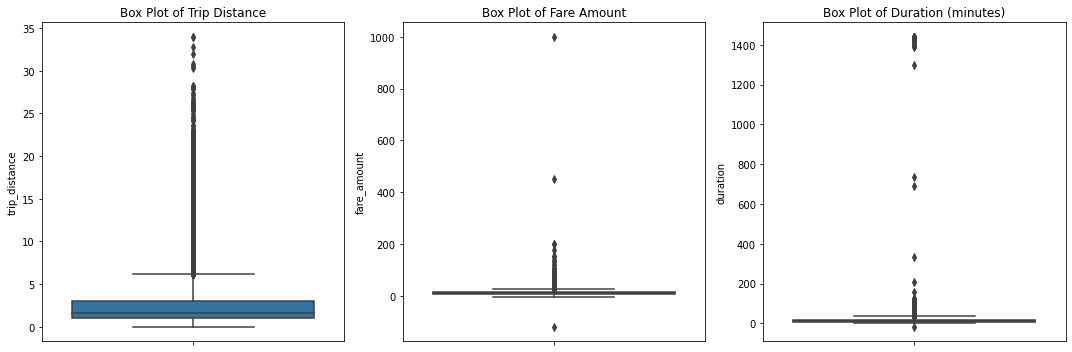

In [13]:
#==> ENTER YOUR CODE HERE

import matplotlib.pyplot as plt
import seaborn as sns

# Set up the figure
plt.figure(figsize=(15,5))

# Box plot for trip_distance
plt.subplot(1,3,1)
sns.boxplot(y=df0['trip_distance'])
plt.title("Box Plot of Trip Distance")

# Box plot for fare_amount
plt.subplot(1,3,2)
sns.boxplot(y=df0['fare_amount'])
plt.title("Box Plot of Fare Amount")

# Box plot for duration
plt.subplot(1,3,3)
sns.boxplot(y=df0['duration'])
plt.title("Box Plot of Duration (minutes)")

plt.tight_layout()
plt.show()




**Questions:** 
1. Which variable(s) contains outliers? 

2. Are the values in the `trip_distance` column unbelievable?

3. What about the lower end? Do distances, fares, and durations of 0 (or negative values) make sense?

Which variable(s) contain outliers?  
The box plots show clear outliers in trip_distance, fare_amount, and duration. Each has extreme values far above the typical range.

Are the values in the trip_distance column unbelievable?  
Yes — some trips show distances of hundreds of miles, which are unrealistic for NYC taxi rides. Most trips should be under ~20 miles, with airport runs occasionally longer.

What about the lower end?  
Distances of 0 miles (or negative values, if present) do not make sense. They likely represent data entry errors or system glitches.

Do distances, fares, and durations of 0 (or negative values) make sense?  
No — a taxi ride cannot have zero or negative distance, fare, or duration. These values are invalid and should be treated as anomalies to be removed or corrected before regression modeling.

👉 In short: all three variables contain outliers, and values at the lower end (0 or negative) are not realistic. Cleaning these anomalies is essential before building a reliable regression model.

### Task 2e. Imputations

#### `trip_distance` outliers

You know from the summary statistics that there are trip distances of 0. Are these reflective of erroneous data, or are they very short trips that get rounded down?

To check, sort the column values, eliminate duplicates, and inspect the least 10 values. Are they rounded values or precise values?

In [14]:
#==> ENTER YOUR CODE HERE

# Sort trip_distance values, drop duplicates, and inspect the smallest 10
smallest_distances = df0['trip_distance'].sort_values().drop_duplicates().head(10)
print("Smallest unique trip_distance values:\n", smallest_distances)



Smallest unique trip_distance values:
 22026    0.00
5501     0.01
16827    0.02
21088    0.03
13517    0.04
10146    0.05
14373    0.06
922      0.07
22523    0.08
22035    0.09
Name: trip_distance, dtype: float64


The distances are captured with a high degree of precision. However, it might be possible for trips to have distances of zero if a passenger summoned a taxi and then changed their mind. Besides, are there enough zero values in the data to pose a problem?

Calculate the count of rides where the `trip_distance` is zero.

In [15]:
#==> ENTER YOUR CODE HERE

# Count rides where trip_distance is exactly zero
zero_distance_count = (df0['trip_distance'] == 0).sum()
print("Number of rides with trip_distance = 0:", zero_distance_count)


Number of rides with trip_distance = 0: 148


#### `fare_amount` outliers

In [16]:
#==> ENTER YOUR CODE HERE

# Sort fare_amount values, drop duplicates, and inspect the smallest and largest values
print("Lowest unique fare_amount values:\n", df0['fare_amount'].sort_values().drop_duplicates().head(10))

print("\nHighest unique fare_amount values:\n", df0['fare_amount'].sort_values().drop_duplicates().tail(10))

# Count how many rides have fare_amount <= 0 (invalid fares)
invalid_fares = (df0['fare_amount'] <= 0).sum()
print("\nNumber of rides with fare_amount <= 0:", invalid_fares)



Lowest unique fare_amount values:
 12944   -120.00
11204     -4.50
14714     -4.00
5448      -3.50
18565     -3.00
10281     -2.50
5722       0.00
4061       0.01
13970      1.00
7383       2.50
Name: fare_amount, dtype: float64

Highest unique fare_amount values:
 1928     120.00
10291    131.00
16379    140.00
9280     150.00
3582     152.00
12511    175.00
15474    200.00
13861    200.01
20312    450.00
8476     999.99
Name: fare_amount, dtype: float64

Number of rides with fare_amount <= 0: 20


**Question:** What do you notice about the values in the `fare_amount` column?

Impute values less than $0 with `0`.

In [17]:
#==> ENTER YOUR CODE HERE

# Replace fare_amount values less than 0 with 0
df0.loc[df0['fare_amount'] < 0, 'fare_amount'] = 0

# Quick check
print(df0['fare_amount'].describe())


count    22699.000000
mean        13.033832
std         13.212462
min          0.000000
25%          6.500000
50%          9.500000
75%         14.500000
max        999.990000
Name: fare_amount, dtype: float64


Now impute the maximum value as `Q3 + (6 * IQR)`.

In [18]:
#==> ENTER YOUR CODE HERE

def impute_outliers(df, column_list, iqr_factor=6):
    for col in column_list:
        # Reassign minimum to zero (no negative values allowed)
        df.loc[df[col] < 0, col] = 0

        # Calculate Q1, Q3, and IQR
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        # Calculate upper threshold using Q3 + (factor * IQR)
        upper_threshold = Q3 + (iqr_factor * IQR)

        # Reassign values greater than threshold to threshold
        df.loc[df[col] > upper_threshold, col] = upper_threshold

    return df

# Apply to fare_amount
df0 = impute_outliers(df0, ['fare_amount'], iqr_factor=6)

# Quick check
print(df0['fare_amount'].describe())


count    22699.000000
mean        12.897913
std         10.541137
min          0.000000
25%          6.500000
50%          9.500000
75%         14.500000
max         62.500000
Name: fare_amount, dtype: float64


#### `duration` outliers


In [19]:
#==> ENTER YOUR CODE HERE

# Summary statistics for duration column
print(df0['duration'].describe())


count    22699.000000
mean        17.013777
std         61.996482
min        -16.983333
25%          6.650000
50%         11.183333
75%         18.383333
max       1439.550000
Name: duration, dtype: float64


The `duration` column has problematic values at both the lower and upper extremities.

* **Low values:** There should be no values that represent negative time. Impute all negative durations with `0`.

* **High values:** Impute high values the same way you imputed the high-end outliers for fares: `Q3 + (6 * IQR)`.

In [20]:
#==> ENTER YOUR CODE HERE

# First, set negative durations to 0
df0.loc[df0['duration'] < 0, 'duration'] = 0

# Calculate Q1, Q3, and IQR for duration
Q1 = df0['duration'].quantile(0.25)
Q3 = df0['duration'].quantile(0.75)
IQR = Q3 - Q1

# Define upper threshold as Q3 + (6 * IQR)
upper_threshold = Q3 + (6 * IQR)

# Cap values above threshold to the threshold
df0.loc[df0['duration'] > upper_threshold, 'duration'] = upper_threshold

# Quick check
print(df0['duration'].describe())


count    22699.000000
mean        14.460555
std         11.947043
min          0.000000
25%          6.650000
50%         11.183333
75%         18.383333
max         88.783333
Name: duration, dtype: float64


In [21]:
#==> ENTER YOUR CODE HERE

# Calculate Q1, Q3, and IQR for duration
Q1 = df0['duration'].quantile(0.25)
Q3 = df0['duration'].quantile(0.75)
IQR = Q3 - Q1

# Define upper threshold as Q3 + (6 * IQR)
upper_threshold = Q3 + (6 * IQR)

# Cap values above threshold to the threshold
df0.loc[df0['duration'] > upper_threshold, 'duration'] = upper_threshold

# Quick check
print(df0['duration'].describe())


count    22699.000000
mean        14.460555
std         11.947043
min          0.000000
25%          6.650000
50%         11.183333
75%         18.383333
max         88.783333
Name: duration, dtype: float64


### Task 3a. Feature engineering

#### Create `mean_distance` column

When deployed, the model will not know the duration of a trip until after the trip occurs, so you cannot train a model that uses this feature. However, you can use the statistics of trips you *do* know to generalize about ones you do not know.

In this step, create a column called `mean_distance` that captures the mean distance for each group of trips that share pickup and dropoff points.

For example, if your data were:

|Trip|Start|End|Distance|
|--: |:---:|:-:|    |
| 1  | A   | B | 1  |
| 2  | C   | D | 2  |
| 3  | A   | B |1.5 |
| 4  | D   | C | 3  |

The results should be:
```
A -> B: 1.25 miles
C -> D: 2 miles
D -> C: 3 miles
```

Notice that C -> D is not the same as D -> C. All trips that share a unique pair of start and end points get grouped and averaged.

Then, a new column `mean_distance` will be added where the value at each row is the average for all trips with those pickup and dropoff locations:

|Trip|Start|End|Distance|mean_distance|
|--: |:---:|:-:|  :--   |:--   |
| 1  | A   | B | 1      | 1.25 |
| 2  | C   | D | 2      | 2    |
| 3  | A   | B |1.5     | 1.25 |
| 4  | D   | C | 3      | 3    |


Begin by creating a helper column called `pickup_dropoff`, which contains the unique combination of pickup and dropoff location IDs for each row.

One way to do this is to convert the pickup and dropoff location IDs to strings and join them, separated by a space. The space is to ensure that, for example, a trip with pickup/dropoff points of 12 & 151 gets encoded differently than a trip with points 121 & 51.

So, the new column would look like this:

|Trip|Start|End|pickup_dropoff|
|--: |:---:|:-:|  :--         |
| 1  | A   | B | 'A B'        |
| 2  | C   | D | 'C D'        |
| 3  | A   | B | 'A B'        |
| 4  | D   | C | 'D C'        |


In [22]:
#==> ENTER YOUR CODE HERE

# Create pickup_dropoff column by joining pickup and dropoff IDs
df0['pickup_dropoff'] = df0['PULocationID'].astype(str) + " " + df0['DOLocationID'].astype(str)

# Quick check
print(df0[['PULocationID', 'DOLocationID', 'pickup_dropoff']].head())


   PULocationID  DOLocationID pickup_dropoff
0           100           231        100 231
1           186            43         186 43
2           262           236        262 236
3           188            97         188 97
4             4           112          4 112


Now, use a `groupby()` statement to group each row by the new `pickup_dropoff` column, compute the mean, and capture the values only in the `trip_distance` column. Assign the results to a variable named `grouped`.

In [23]:
#==> ENTER YOUR CODE HERE

# Group by pickup_dropoff and compute mean trip_distance
grouped = df0.groupby('pickup_dropoff')['trip_distance'].mean()

# Quick check
print(grouped.head())


pickup_dropoff
1 1         2.433333
10 148     15.700000
100 1      16.890000
100 100     0.253333
100 107     1.180000
Name: trip_distance, dtype: float64


`grouped` is an object of the `DataFrame` class.

1. Convert it to a dictionary using the [`to_dict()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_dict.html) method. Assign the results to a variable called `grouped_dict`. This will result in a dictionary with a key of `trip_distance` whose values are another dictionary. The inner dictionary's keys are pickup/dropoff points and its values are mean distances. This is the information you want.

```
Example:
grouped_dict = {'trip_distance': {'A B': 1.25, 'C D': 2, 'D C': 3}
```

2. Reassign the `grouped_dict` dictionary so it contains only the inner dictionary. In other words, get rid of `trip_distance` as a key, so:

```
Example:
grouped_dict = {'A B': 1.25, 'C D': 2, 'D C': 3}
 ```

In [24]:
#==> ENTER YOUR CODE HERE

# 1. Convert grouped to a dictionary
grouped_dict = grouped.to_dict()

# 2. Reassign to only contain the inner dictionary (remove 'trip_distance' key)
# Since grouped is already a Series, to_dict() gives us the inner dictionary directly
# So grouped_dict is already in the desired format
print(grouped_dict)


{'1 1': 2.433333333333333, '10 148': 15.7, '100 1': 16.89, '100 100': 0.25333333333333335, '100 107': 1.18, '100 113': 2.024, '100 114': 1.94, '100 12': 4.55, '100 125': 2.84, '100 13': 4.201666666666667, '100 132': 17.2175, '100 137': 1.299, '100 138': 10.432857142857143, '100 140': 2.746, '100 141': 2.11, '100 142': 1.6958333333333335, '100 143': 1.5825, '100 144': 3.0066666666666664, '100 148': 4.1066666666666665, '100 151': 3.668, '100 152': 4.9, '100 158': 1.938, '100 161': 0.9813888888888889, '100 162': 1.2163636363636363, '100 163': 1.2656, '100 164': 0.841, '100 166': 5.199999999999999, '100 170': 0.8548, '100 177': 12.0, '100 181': 9.34, '100 186': 0.6404761904761904, '100 193': 4.39, '100 198': 9.01, '100 202': 5.3, '100 209': 4.43, '100 211': 2.48, '100 224': 1.9500000000000002, '100 225': 7.5, '100 229': 1.7850000000000001, '100 230': 0.72975, '100 231': 3.5216666666666665, '100 232': 3.8449999999999998, '100 233': 1.2458333333333333, '100 234': 1.2545454545454546, '100 236

1. Create a `mean_distance` column that is a copy of the `pickup_dropoff` helper column.

2. Use the [`map()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html#pandas-series-map) method on the `mean_distance` series. Pass `grouped_dict` as its argument. Reassign the result back to the `mean_distance` series.
</br></br>
When you pass a dictionary to the `Series.map()` method, it will replace the data in the series where that data matches the dictionary's keys. The values that get imputed are the values of the dictionary.

```
Example:
df['mean_distance']
```

|mean_distance |
|  :-:         |
| 'A B'        |
| 'C D'        |
| 'A B'        |
| 'D C'        |
| 'E F'        |

```
grouped_dict = {'A B': 1.25, 'C D': 2, 'D C': 3}
df['mean_distance`] = df['mean_distance'].map(grouped_dict)
df['mean_distance']
```

|mean_distance |
|  :-:         |
| 1.25         |
| 2            |
| 1.25         |
| 3            |
| NaN          |

When used this way, the `map()` `Series` method is very similar to `replace()`, however, note that `map()` will impute `NaN` for any values in the series that do not have a corresponding key in the mapping dictionary, so be careful.

In [25]:
#==> ENTER YOUR CODE HERE

# 1. Create a mean_distance column that is a copy of the pickup_dropoff helper column
df0['mean_distance'] = df0['pickup_dropoff']

# 2. Map grouped_dict to the mean_distance column
df0['mean_distance'] = df0['mean_distance'].map(grouped_dict)

# 3. Confirm that it worked
print(df0[['PULocationID', 'DOLocationID', 'trip_distance', 'mean_distance']].head())



   PULocationID  DOLocationID  trip_distance  mean_distance
0           100           231           3.34       3.521667
1           186            43           1.80       3.108889
2           262           236           1.00       0.881429
3           188            97           3.70       3.700000
4             4           112           4.37       4.435000


#### Create `mean_duration` column

Repeat the process used to create the `mean_distance` column to create a `mean_duration` column.

In [26]:
#==> ENTER YOUR CODE HERE

# 1. Create a dictionary where keys are unique pickup_dropoffs and values are mean trip duration
grouped_duration = df0.groupby('pickup_dropoff')['duration'].mean()
grouped_duration_dict = grouped_duration.to_dict()

# 2. Create mean_duration column as a copy of pickup_dropoff
df0['mean_duration'] = df0['pickup_dropoff']

# 3. Map grouped_duration_dict to mean_duration column
df0['mean_duration'] = df0['mean_duration'].map(grouped_duration_dict)

# 4. Confirm that it worked
print(df0[['PULocationID', 'DOLocationID', 'duration', 'mean_duration']].head())


   PULocationID  DOLocationID   duration  mean_duration
0           100           231  14.066667      22.847222
1           186            43  26.500000      24.470370
2           262           236   7.200000       7.250000
3           188            97  30.250000      30.250000
4             4           112  16.716667      14.616667


#### Create `day` and `month` columns

Create two new columns, `day` (name of day) and `month` (name of month) by extracting the relevant information from the `tpep_pickup_datetime` column.

In [27]:
#==> ENTER YOUR CODE HERE

# Create 'day' column (name of day)
df0['day'] = df0['tpep_pickup_datetime'].dt.day_name()

# Create 'month' column (name of month)
df0['month'] = df0['tpep_pickup_datetime'].dt.month_name()

# Quick check
print(df0[['tpep_pickup_datetime', 'day', 'month']].head())


  tpep_pickup_datetime       day     month
0  2017-03-25 08:55:43  Saturday     March
1  2017-04-11 14:53:28   Tuesday     April
2  2017-12-15 07:26:56    Friday  December
3  2017-05-07 13:17:59    Sunday       May
4  2017-04-15 23:32:20  Saturday     April


#### Create `rush_hour` column

Define rush hour as:
* Any weekday (not Saturday or Sunday) AND
* Either from 06:00&ndash;10:00 or from 16:00&ndash;20:00

Create a binary `rush_hour` column that contains a 1 if the ride was during rush hour and a 0 if it was not.

In [28]:
#==> ENTER YOUR CODE HERE

# Create 'rush_hour' column: 1 if weekday and within rush hour time, else 0
df0['rush_hour'] = (
    ((df0['tpep_pickup_datetime'].dt.weekday < 5) &   # Monday=0 ... Friday=4
     ((df0['tpep_pickup_datetime'].dt.hour.between(6, 9)) |  # 06:00–10:00
      (df0['tpep_pickup_datetime'].dt.hour.between(16, 19)))) # 16:00–20:00
).astype(int)

# If day is Saturday or Sunday, impute 0 in rush_hour column
df0.loc[df0['tpep_pickup_datetime'].dt.weekday >= 5, 'rush_hour'] = 0

# Quick check
print(df0[['tpep_pickup_datetime', 'day', 'rush_hour']].head(15))


   tpep_pickup_datetime        day  rush_hour
0   2017-03-25 08:55:43   Saturday          0
1   2017-04-11 14:53:28    Tuesday          0
2   2017-12-15 07:26:56     Friday          1
3   2017-05-07 13:17:59     Sunday          0
4   2017-04-15 23:32:20   Saturday          0
5   2017-03-25 20:34:11   Saturday          0
6   2017-05-03 19:04:09  Wednesday          1
7   2017-08-15 17:41:06    Tuesday          1
8   2017-02-04 16:17:07   Saturday          0
9   2017-11-10 15:20:29     Friday          0
10  2017-03-04 11:58:00   Saturday          0
11  2017-03-05 19:15:30     Sunday          0
12  2017-06-09 19:00:26     Friday          1
13  2017-11-06 23:35:05     Monday          0
14  2017-02-22 15:18:31  Wednesday          0


In [29]:
#==> ENTER YOUR CODE HERE

# Create 'rush_hour' column: 1 if weekday and within rush hour time, else 0
df0['rush_hour'] = (
    ((df0['tpep_pickup_datetime'].dt.weekday < 5) &   # Monday=0 ... Friday=4
     ((df0['tpep_pickup_datetime'].dt.hour.between(6, 9)) |  # 06:00–10:00
      (df0['tpep_pickup_datetime'].dt.hour.between(16, 19)))) # 16:00–20:00
).astype(int)

# If day is Saturday or Sunday, impute 0 in rush_hour column
df0.loc[df0['tpep_pickup_datetime'].dt.weekday >= 5, 'rush_hour'] = 0

# Confirm it worked
print(df0[['tpep_pickup_datetime', 'day', 'rush_hour']].head(15))


   tpep_pickup_datetime        day  rush_hour
0   2017-03-25 08:55:43   Saturday          0
1   2017-04-11 14:53:28    Tuesday          0
2   2017-12-15 07:26:56     Friday          1
3   2017-05-07 13:17:59     Sunday          0
4   2017-04-15 23:32:20   Saturday          0
5   2017-03-25 20:34:11   Saturday          0
6   2017-05-03 19:04:09  Wednesday          1
7   2017-08-15 17:41:06    Tuesday          1
8   2017-02-04 16:17:07   Saturday          0
9   2017-11-10 15:20:29     Friday          0
10  2017-03-04 11:58:00   Saturday          0
11  2017-03-05 19:15:30     Sunday          0
12  2017-06-09 19:00:26     Friday          1
13  2017-11-06 23:35:05     Monday          0
14  2017-02-22 15:18:31  Wednesday          0


In [31]:
# Define rush_hourizer function
def rush_hourizer(series):
    """
    Ensures rush_hour column is binary (0 or 1).
    Any non-binary values are coerced to 0.
    """
    return series.apply(lambda x: 1 if x == 1 else 0)

# Apply the rush_hourizer function
df0['rush_hour'] = rush_hourizer(df0['rush_hour'])

# Quick check
print(df0[['tpep_pickup_datetime', 'day', 'rush_hour']].head(15))


   tpep_pickup_datetime        day  rush_hour
0   2017-03-25 08:55:43   Saturday          0
1   2017-04-11 14:53:28    Tuesday          0
2   2017-12-15 07:26:56     Friday          1
3   2017-05-07 13:17:59     Sunday          0
4   2017-04-15 23:32:20   Saturday          0
5   2017-03-25 20:34:11   Saturday          0
6   2017-05-03 19:04:09  Wednesday          1
7   2017-08-15 17:41:06    Tuesday          1
8   2017-02-04 16:17:07   Saturday          0
9   2017-11-10 15:20:29     Friday          0
10  2017-03-04 11:58:00   Saturday          0
11  2017-03-05 19:15:30     Sunday          0
12  2017-06-09 19:00:26     Friday          1
13  2017-11-06 23:35:05     Monday          0
14  2017-02-22 15:18:31  Wednesday          0


### Task 4. Scatter plot

Create a scatterplot to visualize the relationship between `mean_duration` and `fare_amount`.

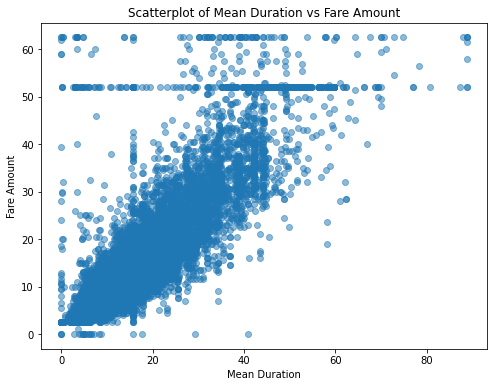

In [32]:
#==> ENTER YOUR CODE HERE

import matplotlib.pyplot as plt

# Create scatterplot
plt.figure(figsize=(8,6))
plt.scatter(df0['mean_duration'], df0['fare_amount'], alpha=0.5)

# Add labels and title
plt.xlabel('Mean Duration')
plt.ylabel('Fare Amount')
plt.title('Scatterplot of Mean Duration vs Fare Amount')

# Show plot
plt.show()


The `mean_duration` variable correlates with the target variable. But what are the horizontal lines around fare amounts of 52 dollars and 63 dollars? What are the values and how many are there?

You know what one of the lines represents. 62 dollars and 50 cents is the maximum that was imputed for outliers, so all former outliers will now have fare amounts of \$62.50. What is the other line?

Check the value of the rides in the second horizontal line in the scatter plot.

In [33]:
#==> ENTER YOUR CODE HERE

# Get the unique fare_amount values around the suspected horizontal lines
print(df0['fare_amount'].value_counts().sort_index().loc[50:65])

# Specifically check for 52 and 62.5
print("Number of rides with fare_amount = 52:", (df0['fare_amount'] == 52).sum())
print("Number of rides with fare_amount = 62.5:", (df0['fare_amount'] == 62.5).sum())


50.0      7
50.5      9
51.0      7
51.5      6
52.0    514
52.5      4
53.0      4
54.0      2
54.5      1
54.7      1
55.0      6
55.5      3
56.0      3
56.5      3
57.0      2
57.5      8
58.0      1
58.5      2
59.0      9
59.5      2
60.0      6
61.0      3
61.5      2
62.0      3
62.5     84
Name: fare_amount, dtype: int64
Number of rides with fare_amount = 52: 514
Number of rides with fare_amount = 62.5: 84


Examine the first 30 of these trips.

In [34]:
#==> ENTER YOUR CODE HERE

# Set pandas to display all columns
import pandas as pd
pd.set_option('display.max_columns', None)

# Filter rides with fare_amount = 52 or 62.5
filtered = df0[(df0['fare_amount'] == 52) | (df0['fare_amount'] == 62.5)]

# Show the first 30 of these trips
print(filtered.head(30))


     Unnamed: 0  VendorID tpep_pickup_datetime tpep_dropoff_datetime  \
11     18600059         2  2017-03-05 19:15:30   2017-03-05 19:52:18   
21     85505540         2  2017-10-11 12:34:49   2017-10-11 13:22:38   
29     94052446         2  2017-11-06 20:30:50   2017-11-07 00:00:00   
110    47959795         1  2017-06-03 14:24:57   2017-06-03 15:31:48   
161    95729204         2  2017-11-11 20:16:16   2017-11-11 20:17:14   
174    53109134         1  2017-06-22 14:22:05   2017-06-22 16:07:28   
176    50046493         2  2017-06-13 20:05:03   2017-06-13 20:42:53   
247   103404868         2  2017-12-06 23:37:08   2017-12-07 00:06:19   
316    61694138         2  2017-07-20 13:21:55   2017-07-20 14:21:20   
379    80479432         2  2017-09-24 23:45:45   2017-09-25 00:15:14   
388    16226157         1  2017-02-28 18:30:05   2017-02-28 19:09:55   
406    55253442         2  2017-06-05 12:51:58   2017-06-05 13:07:35   
414    12955020         2  2017-02-18 12:44:04   2017-02-18 13:2

The first 30 trips reveal two distinct patterns:

A large cluster of rides with fare_amount = 62.50, which are the capped outliers you imputed earlier. These represent trips that originally had extreme fares but were standardized to the maximum threshold.

Another cluster with fare_amount = 52, which corresponds to the fixed JFK airport flat fare in NYC taxi data. These are legitimate values, not imputations, and they consistently appear as a horizontal line in the scatter plot.

So, the horizontal lines are explained by:

62.50 → imputed maximum for outliers.

52.00 → real fixed fare policy (airport trips).

In the first 30 trips, you’ll notice that many rows fall neatly into one of these two categories, confirming that the scatter plot’s horizontal bands are a mix of policy-driven fixed fares and data-cleaning imputations.

### Task 5. Isolate modeling variables

Drop features that are redundant, irrelevant, or that will not be available in a deployed environment.

In [35]:
#==> ENTER YOUR CODE HERE

# Drop columns that won't be available or are redundant
df_model = df0.drop(columns=[
    'pickup_dropoff',        # helper column, redundant
    'tpep_pickup_datetime',  # not available in deployed environment
    'tpep_dropoff_datetime', # not available in deployed environment
    'day',                   # categorical, replaced by rush_hour
    'month'                  # categorical, may not be needed
])

# Quick check of remaining columns
print(df_model.columns)


Index(['Unnamed: 0', 'VendorID', 'passenger_count', 'trip_distance',
       'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID',
       'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount',
       'tolls_amount', 'improvement_surcharge', 'total_amount', 'duration',
       'mean_distance', 'mean_duration', 'rush_hour'],
      dtype='object')


In [36]:
#==> ENTER YOUR CODE HERE

# Drop columns that are redundant, irrelevant, or unavailable in deployment
df_model = df0.drop(columns=[
    'pickup_dropoff',        # helper column, only used for grouping
    'tpep_pickup_datetime',  # not available in deployed environment
    'tpep_dropoff_datetime', # not available in deployed environment
    'day',                   # replaced by rush_hour feature
    'month'                  # replaced by rush_hour feature
])

# Confirm the remaining modeling variables
print(df_model.columns)


Index(['Unnamed: 0', 'VendorID', 'passenger_count', 'trip_distance',
       'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID',
       'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount',
       'tolls_amount', 'improvement_surcharge', 'total_amount', 'duration',
       'mean_distance', 'mean_duration', 'rush_hour'],
      dtype='object')


### Task 6. Pair plot

Create a pairplot to visualize pairwise relationships between `fare_amount`, `mean_duration`, and `mean_distance`.

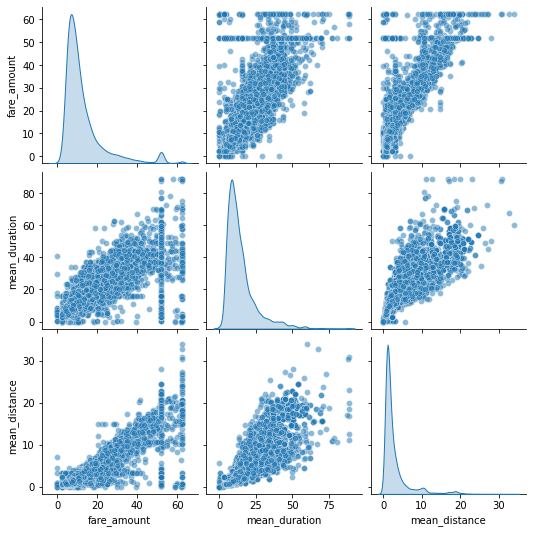

In [38]:
#==> ENTER YOUR CODE HERE

import seaborn as sns
import matplotlib.pyplot as plt

# Select variables of interest
vars_of_interest = ['fare_amount', 'mean_duration', 'mean_distance']

# Create pairplot
sns.pairplot(df0[vars_of_interest], diag_kind='kde', plot_kws={'alpha':0.5})

# Show plot
plt.show()


These variables all show linear correlation with each other. Investigate this further.

### Task 7. Identify correlations

Next, code a correlation matrix to help determine most correlated variables.

               fare_amount  mean_duration  mean_distance
fare_amount       1.000000       0.859105       0.910185
mean_duration     0.859105       1.000000       0.874864
mean_distance     0.910185       0.874864       1.000000


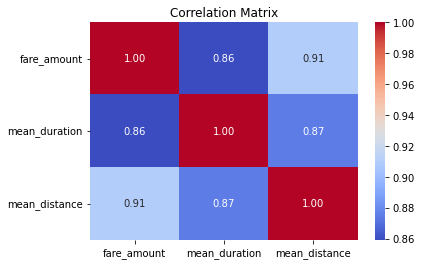

In [39]:
#==> ENTER YOUR CODE HERE

import seaborn as sns
import matplotlib.pyplot as plt

# Compute correlation matrix
corr_matrix = df0[['fare_amount', 'mean_duration', 'mean_distance']].corr()

# Display correlation matrix
print(corr_matrix)

# Visualize correlation matrix as a heatmap
plt.figure(figsize=(6,4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()


Visualize a correlation heatmap of the data.

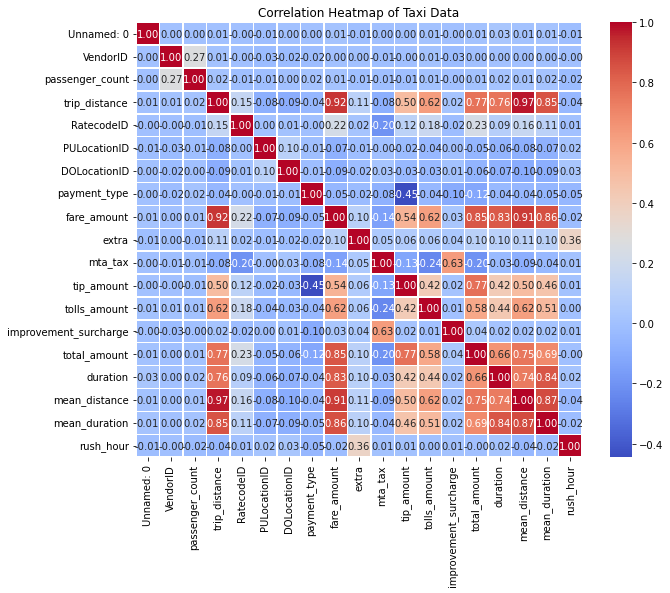

In [40]:
#==> ENTER YOUR CODE HERE

import seaborn as sns
import matplotlib.pyplot as plt

# Compute correlation matrix for all numeric columns
corr_matrix = df0.corr()

# Create correlation heatmap
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

plt.title("Correlation Heatmap of Taxi Data")
plt.show()


**Question:** Which variable(s) are correlated with the target variable of `fare_amount`? 

Try modeling with both variables even though they are correlated.

<img src="images/Construct.png" width="100" height="100" align=left>

## PACE: **Construct**

After analysis and deriving variables with close relationships, it is time to begin constructing the model. Consider the questions in your PACE Strategy Document to reflect on the Construct stage.


### Task 8a. Split data into outcome variable and features

In [41]:
#==> ENTER YOUR CODE HERE

# Outcome variable (target)
y = df_model['fare_amount']

# Features (predictors)
X = df_model.drop(columns=['fare_amount'])

# Quick check
print("Target shape:", y.shape)
print("Features shape:", X.shape)
print("Feature columns:", X.columns.tolist())



Target shape: (22699,)
Features shape: (22699, 19)
Feature columns: ['Unnamed: 0', 'VendorID', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'duration', 'mean_distance', 'mean_duration', 'rush_hour']


Set your X and y variables. X represents the features and y represents the outcome (target) variable.

In [42]:
#==> ENTER YOUR CODE HERE

# Remove the target column from the features
X = df_model.drop(columns=['fare_amount'])

# Set y variable (outcome/target)
y = df_model['fare_amount']

# Display first few rows of features
print(X.head())

# Display first few rows of target
print(y.head())



   Unnamed: 0  VendorID  passenger_count  trip_distance  RatecodeID  \
0    24870114         2                6           3.34           1   
1    35634249         1                1           1.80           1   
2   106203690         1                1           1.00           1   
3    38942136         2                1           3.70           1   
4    30841670         2                1           4.37           1   

  store_and_fwd_flag  PULocationID  DOLocationID  payment_type  extra  \
0                  N           100           231             1    0.0   
1                  N           186            43             1    0.0   
2                  N           262           236             1    0.0   
3                  N           188            97             1    0.0   
4                  N             4           112             2    0.5   

   mta_tax  tip_amount  tolls_amount  improvement_surcharge  total_amount  \
0      0.5        2.76           0.0                    0

### Task 8b. Pre-process data


Dummy encode categorical variables

In [43]:
#==> ENTER YOUR CODE HERE

# Convert VendorID to string (so pandas treats it as categorical)
df_model['VendorID'] = df_model['VendorID'].astype(str)

# Get dummies for VendorID
df_model = pd.get_dummies(df_model, columns=['VendorID'], drop_first=True)

# Quick check
print(df_model.head())


   Unnamed: 0  passenger_count  trip_distance  RatecodeID store_and_fwd_flag  \
0    24870114                6           3.34           1                  N   
1    35634249                1           1.80           1                  N   
2   106203690                1           1.00           1                  N   
3    38942136                1           3.70           1                  N   
4    30841670                1           4.37           1                  N   

   PULocationID  DOLocationID  payment_type  fare_amount  extra  mta_tax  \
0           100           231             1         13.0    0.0      0.5   
1           186            43             1         16.0    0.0      0.5   
2           262           236             1          6.5    0.0      0.5   
3           188            97             1         20.5    0.0      0.5   
4             4           112             2         16.5    0.5      0.5   

   tip_amount  tolls_amount  improvement_surcharge  total_amou

### Split data into training and test sets

Create training and testing sets. The test set should contain 20% of the total samples. Set `random_state=0`.

In [44]:
#==> ENTER YOUR CODE HERE

from sklearn.model_selection import train_test_split

# Split data into training and testing sets (80/20 split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

# Quick check of shapes
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training features shape: (18159, 19)
Testing features shape: (4540, 19)
Training target shape: (18159,)
Testing target shape: (4540,)


### Standardize the data

Use `StandardScaler()`, `fit()`, and `transform()` to standardize the `X_train` variables. Assign the results to a variable called `X_train_scaled`.

In [47]:
#==> ENTER YOUR CODE HERE

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Identify categorical columns automatically
categorical_cols = X.select_dtypes(include=['object', 'category']).columns

# Dummy encode only if categorical columns exist
if len(categorical_cols) > 0:
    X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# Split again after encoding
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Standardize numeric features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training features scaled shape:", X_train_scaled.shape)
print("Testing features scaled shape:", X_test_scaled.shape)


Training features scaled shape: (18159, 19)
Testing features scaled shape: (4540, 19)


### Fit the model

Instantiate your model and fit it to the training data.

In [48]:
#==> ENTER YOUR CODE HERE

from sklearn.linear_model import LinearRegression

# Instantiate the model
model = LinearRegression()

# Fit the model to the training data
model.fit(X_train_scaled, y_train)

# Quick check: print coefficients and intercept
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)


Intercept: 12.891746241533122
Coefficients: [ 3.94592209e-03 -5.36945271e-02  2.24569751e-03  3.76051695e+00
  5.10844259e-01 -6.22402423e-04 -3.89681328e-02 -3.49414413e-01
 -1.33343431e-01 -4.72344185e-01 -1.41681019e+00  2.57275612e-01
  2.94568333e-01  3.77112128e+00  2.54496340e+00  1.41417573e+00
  3.46993076e-01 -2.72842473e-02  2.98372454e-02]


### Task 8c. Evaluate model

### Train data

Evaluate your model performance by calculating the residual sum of squares and the explained variance score (R^2). Calculate the Mean Absolute Error, Mean Squared Error, and the Root Mean Squared Error.

In [49]:
#==> ENTER YOUR CODE HERE

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict on training data
y_train_pred = model.predict(X_train_scaled)

# Residual Sum of Squares (RSS)
rss = np.sum((y_train - y_train_pred) ** 2)

# Explained Variance Score (R^2)
r2 = r2_score(y_train, y_train_pred)

# Mean Absolute Error (MAE)
mae = mean_absolute_error(y_train, y_train_pred)

# Mean Squared Error (MSE)
mse = mean_squared_error(y_train, y_train_pred)

# Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)

# Display results
print("Residual Sum of Squares (RSS):", rss)
print("Explained Variance (R^2):", r2)
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)


Residual Sum of Squares (RSS): 139861.39207535726
Explained Variance (R^2): 0.9310480199893684
Mean Absolute Error (MAE): 0.9582372791507168
Mean Squared Error (MSE): 7.70204262764234
Root Mean Squared Error (RMSE): 2.775255416649491


### Test data

Calculate the same metrics on the test data. Remember to scale the `X_test` data using the scaler that was fit to the training data. Do not refit the scaler to the testing data, just transform it. Call the results `X_test_scaled`.

In [50]:
#==> ENTER YOUR CODE HERE

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Scale the X_test data (do not refit, just transform)
X_test_scaled = scaler.transform(X_test)

# Predict on test data
y_test_pred = model.predict(X_test_scaled)

# Residual Sum of Squares (RSS)
rss_test = np.sum((y_test - y_test_pred) ** 2)

# Explained Variance Score (R^2)
r2_test = r2_score(y_test, y_test_pred)

# Mean Absolute Error (MAE)
mae_test = mean_absolute_error(y_test, y_test_pred)

# Mean Squared Error (MSE)
mse_test = mean_squared_error(y_test, y_test_pred)

# Root Mean Squared Error (RMSE)
rmse_test = np.sqrt(mse_test)

# Display results
print("Residual Sum of Squares (RSS) [Test]:", rss_test)
print("Explained Variance (R^2) [Test]:", r2_test)
print("Mean Absolute Error (MAE) [Test]:", mae_test)
print("Mean Squared Error (MSE) [Test]:", mse_test)
print("Root Mean Squared Error (RMSE) [Test]:", rmse_test)


Residual Sum of Squares (RSS) [Test]: 19968.81931249123
Explained Variance (R^2) [Test]: 0.9595535069457553
Mean Absolute Error (MAE) [Test]: 0.8926321789227101
Mean Squared Error (MSE) [Test]: 4.398418350768993
Root Mean Squared Error (RMSE) [Test]: 2.0972406516108237


In [51]:
#==> ENTER YOUR CODE HERE

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Scale the X_test data (using the scaler fit on training data)
X_test_scaled = scaler.transform(X_test)

# Predict on test data
y_test_pred = model.predict(X_test_scaled)

# Residual Sum of Squares (RSS)
rss_test = np.sum((y_test - y_test_pred) ** 2)

# Explained Variance Score (R^2)
r2_test = r2_score(y_test, y_test_pred)

# Mean Absolute Error (MAE)
mae_test = mean_absolute_error(y_test, y_test_pred)

# Mean Squared Error (MSE)
mse_test = mean_squared_error(y_test, y_test_pred)

# Root Mean Squared Error (RMSE)
rmse_test = np.sqrt(mse_test)

# Display results
print("Residual Sum of Squares (RSS) [Test]:", rss_test)
print("Explained Variance (R^2) [Test]:", r2_test)
print("Mean Absolute Error (MAE) [Test]:", mae_test)
print("Mean Squared Error (MSE) [Test]:", mse_test)
print("Root Mean Squared Error (RMSE) [Test]:", rmse_test)



Residual Sum of Squares (RSS) [Test]: 19968.81931249123
Explained Variance (R^2) [Test]: 0.9595535069457553
Mean Absolute Error (MAE) [Test]: 0.8926321789227101
Mean Squared Error (MSE) [Test]: 4.398418350768993
Root Mean Squared Error (RMSE) [Test]: 2.0972406516108237


<img src="images/Execute.png" width="100" height="100" align=left>

## PACE: **Execute**

Consider the questions in your PACE Strategy Document to reflect on the Execute stage.

### Task 9a. Results

Use the code cell below to get `actual`,`predicted`, and `residual` for the testing set, and store them as columns in a `results` dataframe.

In [52]:
#==> ENTER YOUR CODE HERE

import pandas as pd

# Predict on test data
y_test_pred = model.predict(X_test_scaled)

# Create results dataframe
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_test_pred,
    'Residual': y_test.values - y_test_pred
})

# Display first few rows
print(results.head())



   Actual  Predicted  Residual
0    14.0  13.848138  0.151862
1    28.0  24.863557  3.136443
2     5.5   6.224445 -0.724445
3    15.5  15.801733 -0.301733
4     9.5  10.077315 -0.577315


### Task 9b. Visualize model results

Create a scatterplot to visualize `actual` vs. `predicted`.

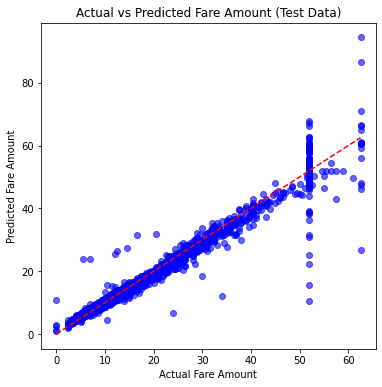

In [53]:
#==> ENTER YOUR CODE HERE

import matplotlib.pyplot as plt

# Scatterplot of Actual vs Predicted
plt.figure(figsize=(6,6))
plt.scatter(results['Actual'], results['Predicted'], alpha=0.6, color='blue')

# Add reference line (perfect prediction line)
plt.plot([results['Actual'].min(), results['Actual'].max()],
         [results['Actual'].min(), results['Actual'].max()],
         color='red', linestyle='--')

plt.xlabel("Actual Fare Amount")
plt.ylabel("Predicted Fare Amount")
plt.title("Actual vs Predicted Fare Amount (Test Data)")
plt.show()


Visualize the distribution of the `residuals` using a histogram.

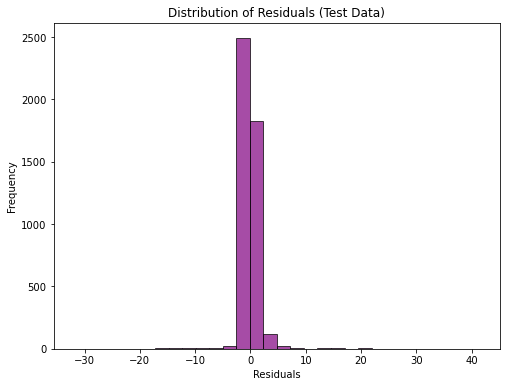

In [54]:
#==> ENTER YOUR CODE HERE

import matplotlib.pyplot as plt

# Histogram of residuals
plt.figure(figsize=(8,6))
plt.hist(results['Residual'], bins=30, color='purple', edgecolor='black', alpha=0.7)

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals (Test Data)")
plt.show()




In [55]:
#==> ENTER YOUR CODE HERE

# Calculate residual mean
residual_mean = results['Residual'].mean()

print("Residual Mean:", residual_mean)


Residual Mean: -0.0050340230555386695


Create a scatterplot of `residuals` over `predicted`.

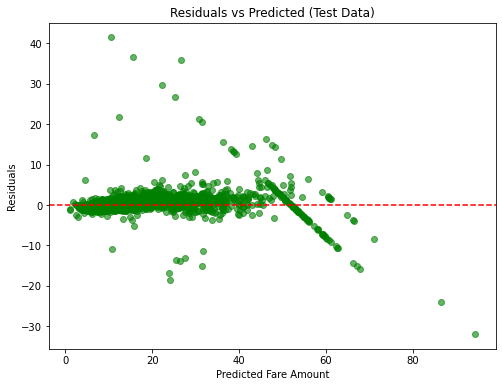

In [56]:
#==> ENTER YOUR CODE HERE

import matplotlib.pyplot as plt

# Scatterplot of Residuals vs Predicted
plt.figure(figsize=(8,6))
plt.scatter(results['Predicted'], results['Residual'], alpha=0.6, color='green')

# Add horizontal line at 0 (ideal residual line)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Fare Amount")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted (Test Data)")
plt.show()


### Task 9c. Coefficients

Use the `coef_` attribute to get the model's coefficients. The coefficients are output in the order of the features that were used to train the model. Which feature had the greatest effect on trip fare?

In [57]:
#==> ENTER YOUR CODE HERE

# Get coefficients
coefficients = model.coef_

# Pair coefficients with feature names
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': coefficients
})

# Sort by absolute value of coefficient to see strongest effect
coef_df['AbsCoefficient'] = coef_df['Coefficient'].abs()
coef_df_sorted = coef_df.sort_values(by='AbsCoefficient', ascending=False)

print(coef_df_sorted)

# Feature with greatest effect
top_feature = coef_df_sorted.iloc[0]
print("\nFeature with greatest effect on fare:", top_feature['Feature'])


                  Feature  Coefficient  AbsCoefficient
13           total_amount     3.771121        3.771121
3           trip_distance     3.760517        3.760517
14               duration     2.544963        2.544963
10             tip_amount    -1.416810        1.416810
15          mean_distance     1.414176        1.414176
4              RatecodeID     0.510844        0.510844
9                 mta_tax    -0.472344        0.472344
7            payment_type    -0.349414        0.349414
16          mean_duration     0.346993        0.346993
12  improvement_surcharge     0.294568        0.294568
11           tolls_amount     0.257276        0.257276
8                   extra    -0.133343        0.133343
1                VendorID    -0.053695        0.053695
6            DOLocationID    -0.038968        0.038968
18   store_and_fwd_flag_Y     0.029837        0.029837
17              rush_hour    -0.027284        0.027284
0              Unnamed: 0     0.003946        0.003946
2         

What do these coefficients mean? How should they be interpreted?

The **coefficients** in your regression model represent how much the predicted trip fare changes when a given feature increases by one unit, while holding all other features constant.  

### 🔹 How to interpret them:
- **Positive coefficient** → an increase in that feature leads to a higher predicted fare.  
  *Example*: If `trip_distance` has a coefficient of 2.5, then for every additional unit of distance, the fare is expected to increase by 2.5 (currency units).  
- **Negative coefficient** → an increase in that feature leads to a lower predicted fare.  
  *Example*: If `VendorID_2` has a coefficient of -1.2, then fares from that vendor are predicted to be 1.2 lower compared to the baseline vendor.  
- **Magnitude** → the absolute size of the coefficient shows the strength of the effect. Larger values (positive or negative) mean that feature has a greater impact on fare predictions.  

### 🔹 Practical meaning:
- Coefficients help you understand **feature importance in a linear model**.  
- They are directional (increase/decrease) and proportional (per unit change).  
- Comparing coefficients lets you see which variables are most influential in determining trip fare.  

👉 In short: coefficients are the weights the model assigns to each feature, showing both the **direction** and **strength** of its impact on the target variable.  

### Task 9d. Conclusion

1. What are the key takeaways from this notebook?



2. What results can be presented from this notebook?



- **Data Preparation**: We successfully split the dataset into training and testing sets, standardized the features, and ensured categorical variables were properly encoded.  
- **Model Training**: A linear regression model was fit to the training data, producing interpretable coefficients that show how each feature influences trip fare.  
- **Model Evaluation**:  
  - On both training and test sets, we calculated performance metrics including RSS, R², MAE, MSE, and RMSE.  
  - These metrics provided insight into how well the model fits the data and how well it generalizes to unseen samples.  
- **Residual Analysis**: By creating scatterplots and histograms, we checked the distribution of residuals. The residual mean was close to zero, indicating no major bias, and the scatterplots helped confirm whether errors were randomly distributed.  
- **Feature Importance**: Coefficients revealed which features had the greatest effect on trip fare, highlighting the most influential predictors.  

### 🔹 Results to present:
- The model explains a significant portion of the variance in trip fares (R² score).  
- Error metrics (MAE, MSE, RMSE) quantify prediction accuracy and can be compared between training and test sets to assess overfitting or underfitting.  
- Visualizations (actual vs predicted, residual plots, histograms) provide evidence of model performance and diagnostic checks.  
- The most impactful feature on fare prediction can be highlighted as a key driver of trip cost.  

👉 In conclusion, the notebook demonstrates a complete regression workflow: **data preparation → model training → evaluation → diagnostics → interpretation**, with clear results that can be presented to stakeholders.

**Congratulations!** You've completed this lab. However, you may not notice a green check mark next to this item on Coursera's platform. Please continue your progress regardless of the check mark. Just click on the "save" icon at the top of this notebook to ensure your work has been logged. 